In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [11]:
# Read image in grayscale
image = cv2.imread('images.jpg', cv2.IMREAD_GRAYSCALE)

# Check whether the image loaded successfully
if image is None:
    raise FileNotFoundError("Please check the path of images.jpg")

# Convert grayscale image to binary
_, binary = cv2.threshold(image, 200, 255, cv2.THRESH_BINARY)

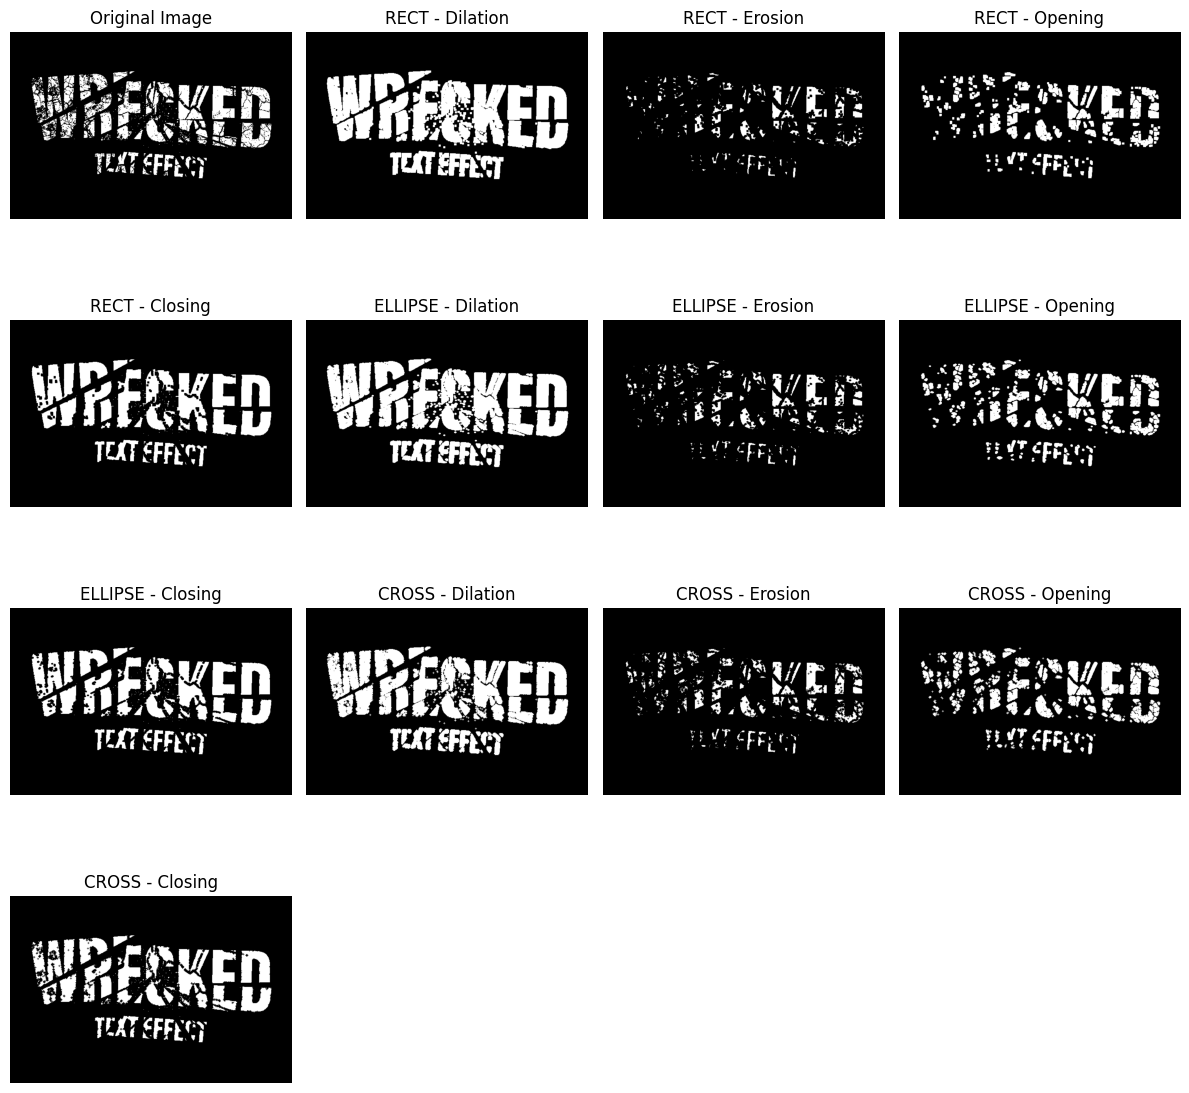

In [12]:
# Different structuring elements
kernels = {
    'RECT': cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5)),
    'ELLIPSE': cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)),
    'CROSS': cv2.getStructuringElement(cv2.MORPH_CROSS, (5, 5))
}

# Display original image
plt.figure(figsize=(12, 12))
plt.subplot(4, 4, 1)
plt.imshow(binary, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plot_index = 2

# Apply morphological operations using each kernel
for name, kernel in kernels.items():

    dilated = cv2.dilate(binary, kernel, iterations=1)
    eroded = cv2.erode(binary, kernel, iterations=1)
    opened = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
    closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

    results = [
        (dilated, f'{name} - Dilation'),
        (eroded, f'{name} - Erosion'),
        (opened, f'{name} - Opening'),
        (closed, f'{name} - Closing')
    ]

    for result, title in results:
        plt.subplot(4, 4, plot_index)
        plt.imshow(result, cmap='gray')
        plt.title(title)
        plt.axis('off')
        plot_index += 1

plt.tight_layout()
plt.show()